<a href="https://colab.research.google.com/github/ELawrence421/skills-introduction-to-github/blob/main/Milestone_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Milestone One: Gathering your Team, Understanding the Problem,  Exploring the Data

#### Due: Midnight on July 20th (with 2-hour grace period)

#### There will be no late period on this homework, as we need to start manual grading immediately!



### What We Will Do in This Milestone Assignment

1. You will convene your team and fill out the Team Contract (in the Homework Repo), to be submitted to Gradescope.
2. You must select a team leader for the purpose of submitting this notebook, after the team collaborates to complete the assignment.
3. At the conclusion of your work on this Milestone, you will complete an Individual Evaluation of your team's work (in the Homework Repo) and upload it *individually* to Gradescope.
4. We will follow a simplified version of the **Machine Learning Project Checklist** in Appendix A in our textbook *Hands-On Machine Learning* (pp.779):  

>Part 1:	Frame the problem and look at the big picture  
Part 2: Download and perform preliminary exploration of the data  
Part 3: Clean the Data: Drop, Impute, and Encode   
Part 4: Explore Feature Relationships  
Part 5: Investigate Feature Engineering options to better expose the underlying data patterns  

### The Dataset

All teams will use the same dataset. It is a smaller version of the Zillow housing dataset that was used in the
Zillow Million Dollar Prize which ran on Kaggle in 2017 (sorry, the contest is closed, so you can't win any money
with this project!).  We will try to predict the assessed tax value (`'taxvaluedollarcnt'`) of the property from a large collection
of descriptors. Some features are closely related and some are obviously useless.  There are potential outliers and also quite a few missing values.

This is a good example of a dataset which has not been predigested for you on Kaggle, and should give you a good chance to
try all the various tools in your toolbox!


### Import

In [ ]:
# =============================
# Useful Imports
# =============================

# Standard Libraries
import os
import time
import math
import io
import zipfile
import requests
from urllib.parse import urlparse
from itertools import chain, combinations

# Data Science Libraries
import numpy as np
import pandas as pd
import seaborn as sns

# Visualization
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as mticker  # Optional: Format y-axis labels as dollars

# Scikit-learn (Machine Learning)
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV,
    RepeatedKFold
)
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error
from sklearn.feature_selection import SequentialFeatureSelector, f_regression, SelectKBest
from sklearn.datasets import make_regression
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, GradientBoostingRegressor

# Kaggle and Progress Tracking
from tqdm import tqdm

# =============================
# Global Variables
# =============================
random_state = 42

# =============================
# Utility Functions
# =============================

# Format y-axis labels as dollars with commas (optional)
def dollar_format(x, pos):
    return f'${x:,.0f}'

# Convert seconds to HH:MM:SS format
def format_hms(seconds):
    return time.strftime("%H:%M:%S", time.gmtime(seconds))



## Prelude: Download the Zillow Housing Dataset

The code cell below will load the dataset for you.    

> **Notice that before downloading, this cell first checks whether the files already exist.**

For a detailed description of the dataset features, please refer to  **Appendix 1** below.

**Note:** Do **not** perform a train/test split for this milestone (unlike HOML suggests), since you need to do the split **after** any data preparation and feature engineering. You can wait until Milestone 2 to do the split.

In [ ]:

url = "https://www.cs.bu.edu/fac/snyder/cs505/Data/zillow_dataset.csv"

filename = os.path.basename(urlparse(url).path)

if not os.path.exists(filename):
    try:
        print("Downloading the file...")
        response = requests.get(url)
        response.raise_for_status()  # Raise an error for bad status codes
        with open(filename, "wb") as f:
            f.write(response.content)
        print("File downloaded successfully.")
    except requests.exceptions.RequestException as e:
        print(f"Error downloading the file: {e}")
else:
    print("File already exists. Skipping download.")

df = pd.read_csv(filename)

File downloaded successfully.


## Part 1: Frame the problem and look at the big picture [3 pts]

This part is a bit vague, since this project is not taking place in an actual business, but for the sake of exercizing all the steps, **pretend** that you are working at Zillow as a data analyst and are given this dataset and asked to
- Analyze and understand the data;
- Create a regression model;
- Give a presentation to the marketing team about your results.  

#### **1 Discussion:**

AFTER doing your EDA, come back and answer each of the following 3 questions in a *concise and informative paragraph between the lines;* you may wish to use your own business or home-buying experience, or to do some online research about the issues before you propose your ideas. (Don't stress about this, but *humor your professor and give it your best shot!*)


**1.1:**  What is the objective of this project in business terms?


The objective of this project is to help Zillow better understand the key property features that influence home tax value, so the company can create a predictive model that estimates home values more accurately. This can support Zillow’s pricing algorithms, improve user trust in property estimates, and help buyers, sellers, and real estate agents make informed decisions. From a business perspective, it also enhances the platform’s credibility and drives engagement through more reliable listings.



**1.2:**  How will your solution be used?


The solution will be used to build a regression model that estimates property tax values based on characteristics such as location, square footage, number of bedrooms, and quality ratings. The marketing team can use these insights to target specific market segments, highlight undervalued properties, or personalize recommendations. Additionally, Zillow’s product team could integrate the model into the Zestimate tool to improve its accuracy and user appeal.

**1.3:**  How should success (or failure) be measured?


Success should be measured by how accurately the model predicts tax values on new, unseen properties. This can be quantified using metrics such as Root Mean Squared Error (RMSE) or Mean Absolute Error (MAE) on a validation dataset. From a business standpoint, success could also be reflected in higher user engagement, increased time spent on property pages, or improvements in conversion rates for home inquiries and purchases. Failure would be indicated by high error rates, misleading value estimates, or a model that fails to generalize beyond the training data.




## Part 2: Download and perform preliminary exploration of the data [4 pts]

### Part 2.A: Load the data into a dataframe and study each feature/column and its characteristics:
- Name
- Type (categorical, int/float, text, etc.)
- Apparent usefulness for the task
- Approximate % of missing values
- How many unique values

**Note:** The **target** is the last column `'taxvaluedollarcnt'` -- pay particular attention to this during the EDA process.
  
Hint: Just use `.head()`, `.info()`, and `.nunique()`.

In [ ]:
pd.set_option('display.max_columns', None)
df.head()

,parcelid,airconditioningtypeid,architecturalstyletypeid,basementsqft,bathroomcnt,bedroomcnt,buildingclasstypeid,buildingqualitytypeid,calculatedbathnbr,decktypeid,finishedfloor1squarefeet,calculatedfinishedsquarefeet,finishedsquarefeet12,finishedsquarefeet13,finishedsquarefeet15,finishedsquarefeet50,finishedsquarefeet6,fips,fireplacecnt,fullbathcnt,garagecarcnt,garagetotalsqft,hashottuborspa,heatingorsystemtypeid,latitude,longitude,lotsizesquarefeet,poolcnt,poolsizesum,pooltypeid10,pooltypeid2,pooltypeid7,propertycountylandusecode,propertylandusetypeid,propertyzoningdesc,rawcensustractandblock,regionidcity,regionidcounty,regionidneighborhood,regionidzip,roomcnt,storytypeid,threequarterbathnbr,typeconstructiontypeid,unitcnt,yardbuildingsqft17,yardbuildingsqft26,yearbuilt,numberofstories,fireplaceflag,assessmentyear,taxdelinquencyflag,taxdelinquencyyear,censustractandblock,taxvaluedollarcnt
0,14297519,NaN,NaN,NaN,3.5,4.0,NaN,NaN,3.5,NaN,NaN,3100.0,3100.0,NaN,NaN,NaN,NaN,6059.0,NaN,3.0,2.0,633.0,NaN,NaN,33634931.0,-117869207.0,4506.0,NaN,NaN,NaN,NaN,NaN,122,261.0,NaN,6.059063e+07,53571.0,1286.0,NaN,96978.0,0.0,NaN,1.0,NaN,NaN,NaN,NaN,1998.0,NaN,NaN,2016.0,NaN,NaN,6.059063e+13,1023282.0
1,17052889,NaN,NaN,NaN,1.0,2.0,NaN,NaN,1.0,NaN,1465.0,1465.0,1465.0,NaN,NaN,1465.0,NaN,6111.0,1.0,1.0,1.0,0.0,NaN,NaN,34449266.0,-119281531.0,12647.0,NaN,NaN,NaN,NaN,NaN,1110,261.0,NaN,6.111001e+07,13091.0,2061.0,NaN,97099.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN,1967.0,1.0,NaN,2016.0,NaN,NaN,6.111001e+13,464000.0
2,14186244,NaN,NaN,NaN,2.0,3.0,NaN,NaN,2.0,NaN,NaN,1243.0,1243.0,NaN,NaN,NaN,NaN,6059.0,NaN,2.0,2.0,440.0,NaN,NaN,33886168.0,-117823170.0,8432.0,1.0,NaN,NaN,NaN,1.0,122,261.0,NaN,6.059022e+07,21412.0,1286.0,NaN,97078.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN,1962.0,1.0,NaN,2016.0,NaN,NaN,6.059022e+13,564778.0
3,12177905,NaN,NaN,NaN,3.0,4.0,NaN,8.0,3.0,NaN,NaN,2376.0,2376.0,NaN,NaN,NaN,NaN,6037.0,NaN,3.0,NaN,NaN,NaN,2.0,34245180.0,-118240722.0,13038.0,1.0,NaN,NaN,NaN,1.0,0101,261.0,LCR110000*,6.037300e+07,396551.0,3101.0,NaN,96330.0,0.0,NaN,NaN,NaN,1.0,NaN,NaN,1970.0,NaN,NaN,2016.0,NaN,NaN,6.037300e+13,145143.0
4,10887214,1.0,NaN,NaN,3.0,3.0,NaN,8.0,3.0,NaN,NaN,1312.0,1312.0,NaN,NaN,NaN,NaN,6037.0,NaN,3.0,NaN,NaN,NaN,2.0,34185120.0,-118414640.0,278581.0,1.0,NaN,NaN,NaN,1.0,010C,266.0,LAR3,6.037124e+07,12447.0,3101.0,268548.0,96451.0,0.0,NaN,NaN,NaN,1.0,NaN,NaN,1964.0,NaN,NaN,2016.0,NaN,NaN,6.037124e+13,119407.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77613 entries, 0 to 77612
Data columns (total 55 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   parcelid                      77613 non-null  int64  
 1   airconditioningtypeid         25007 non-null  float64
 2   architecturalstyletypeid      207 non-null    float64
 3   basementsqft                  50 non-null     float64
 4   bathroomcnt                   77579 non-null  float64
 5   bedroomcnt                    77579 non-null  float64
 6   buildingclasstypeid           15 non-null     float64
 7   buildingqualitytypeid         49809 non-null  float64
 8   calculatedbathnbr             76963 non-null  float64
 9   decktypeid                    614 non-null    float64
 10  finishedfloor1squarefeet      6037 non-null   float64
 11  calculatedfinishedsquarefeet  77378 non-null  float64
 12  finishedsquarefeet12          73923 non-null  float64
 13  f

In [ ]:
df.nunique()

,0
parcelid,77414
airconditioningtypeid,5
architecturalstyletypeid,5
basementsqft,43
bathroomcnt,22
bedroomcnt,16
buildingclasstypeid,2
buildingqualitytypeid,12
calculatedbathnbr,21
decktypeid,1


In [ ]:
for col in df.columns:
    print(f"Column '{col}' unique values: {df[col].unique()}\n")

Column 'parcelid' unique values: [14297519 17052889 14186244 ... 17239384 12773139 12826780]

Column 'airconditioningtypeid' unique values: [nan  1. 13.  5. 11.  9.]

Column 'architecturalstyletypeid' unique values: [nan  7.  8. 21.  3.  2.]

Column 'basementsqft' unique values: [  nan  900. 1416.  224.  100.  512.  380.  204.  515.  273.  200.   90.
 3112.  405.  674. 1252.  912.  254. 3560.  352.  168.  394. 1218.  300.
  280.  800.  600.  700.  640.  819. 1809.  604.  126.  588.  314.  669.
  786.  396.  112.  645.  384. 1969.  252.   38.]

Column 'bathroomcnt' unique values: [ 3.5  1.   2.   3.   0.   2.5  4.5  4.   5.   6.5  1.5  6.   5.5  nan
  7.   9.   8.  10.  11.  18.   7.5 13.   8.5]

Column 'bedroomcnt' unique values: [ 4.  2.  3.  0.  6.  5.  1.  7.  8. nan 12. 10.  9. 14. 11. 16. 13.]

Column 'buildingclasstypeid' unique values: [nan  4.  3.]

Column 'buildingqualitytypeid' unique values: [nan  8.  9.  5.  4.  6.  7. 10.  3. 11. 12.  1.  2.]

Column 'calculatedbathnbr' un

In [ ]:
# Generate a summary of data types, missing %, and unique values
df_summary = pd.DataFrame({
    'Name': df.columns,
    'Type': df.dtypes.values,
    'Missing %': df.isnull().mean().values * 100,
    'Unique Values': df.nunique().values
})

# Display top rows of the summary
df_summary = df_summary.sort_values(by='Missing %', ascending=False)
df_summary.reset_index(drop=True, inplace=True)
df_summary  # or just print(df_summary)


,Name,Type,Missing %,Unique Values
0,buildingclasstypeid,float64,99.980673,2
1,finishedsquarefeet13,float64,99.945885,13
2,basementsqft,float64,99.935578,43
3,storytypeid,float64,99.935578,1
4,yardbuildingsqft26,float64,99.909809,59
5,fireplaceflag,object,99.778388,1
6,architecturalstyletypeid,float64,99.733292,5
7,typeconstructiontypeid,float64,99.712677,4
8,finishedsquarefeet6,float64,99.502661,350
9,pooltypeid10,float64,99.400874,1


#### **2.A Discussion:** Answer the following questions.

**2.A.1:**  Which features are categorical?

The following features are categorical because they either represent type codes, group identifiers, or text labels, even if they appear as float64 or object in the data:

* **airconditioningtypeid** (Type code for A/C)

* **architecturalstyletypeid** (Type code for architectural style)

* **buildingclasstypeid** (Type code for building framing)

* **buildingqualitytypeid** (Ordinal quality rating (e.g., 1–12))

* **decktypeid** (Deck type code)

* **fips** (County identifier code)

* **heatingorsystemtypeid** (Heating system code)

* **pooltypeid10**, **pooltypeid2**, **pooltypeid7** (Pool/spa type codes)

* **propertylandusetypeid** (Property land use code)

* **propertycountylandusecode** (Categorical (object) land use text)

* **propertyzoningdesc** (Categorical (object) zoning description)

* **regionidcity**, **regionidcounty**, **regionidneighborhood**, **regionidzip** (Geographic region codes)

* **storytypeid** (Type of story (e.g., basement, attic)

* **typeconstructiontypeid** (Construction material type)

* **taxdelinquencyflag** (Delinquency flag)

* **fireplaceflag**  (Binary flag)

* **hashottuborspa** (Binary flag)



**2.A.2:**  Are there any features which appear at first glance to be **useless** for the business purpose of this project and should be deleted?  Give examples and describe your reasoning briefly.

* **parcelid**, **censustractandblock**, and **rawcensustractandblock** act as unique identifiers. (They do not contain meaningful patterns that would help predict tax value and could introduce unnecessary noise into the model)
* All features with only one unique value such as, **assessmentyear**, **fireplaceflag**, and **poolcnt**. (They provide no variability or useful signal and should be removed. These columns do not help the model differentiate between properties)

**2.A.3:**  Are there any features which appear to be **useless** because of the percentage of missing values?  If so, give an example.

* **buildingclasstypeid** (99.980673% Missing - Almost all values missing)
* **finishedsquarefeet13** (99.945885% Missing - Almost all values missing)
* **basementsqft** (99.935578% Missing - Almost all values missing)
* **storytypeid**	(99.935578% Missing - Almost all values missing)
* **yardbuildingsqft26**	(99.909809% Missing - Almost all values missing)
* **fireplaceflag**	(99.778388% Missing - Almost all values missing)
*	**architecturalstyletypeid** (99.733292% Missing - Almost all values missing)
*	**typeconstructiontypeid**	(99.712677% Missing - Almost all values missing)
*	**finishedsquarefeet6**	(99.502661% Missing - Almost all values missing)
*	**pooltypeid10**	(99.400874% Missing - Almost all values missing)
*	**decktypeid**	(99.208895% Missing - Almost all values missing)
*	**poolsizesum** (98.880342% Missing - Almost all values missing)
*	**pooltypeid2** (98.616211% Missing - Almost all values missing)
*	**hashottuborspa**	(98.017085% Missing - Almost all values missing)
*	**yardbuildingsqft17**	(96.916754% Missing - Almost all values missing)
*	**taxdelinquencyyear**	(96.263513% Missing - Almost all values missing)
*	**taxdelinquencyflag**	(96.263513% Missing - Almost all values missing)
*	**finishedsquarefeet15** (96.099880% Missing - Almost all values missing)
* **finishedsquarefeet50** (92.221664% Missing - Almost all values missing)
* **finishedfloor1squarefeet**	(92.221664% Missing - Almost all values missing)

I chose to drop features with more than 90% missing values, as they provide limited information and could introduce bias or noise during model training.




**2.A.4:**  Are there any features which appear to be **useless** because of the number of unique values?  If so, give an example.

*   **storytypeid**	(1 Unique Value - Constant)
*   **fireplaceflag**	(1 Unique Value - Constant)
*   **pooltypeid10**	(1 Unique Value - Constant)
*   **decktypeid**	(1 Unique Value - Constant)
*   **pooltypeid2**	(1 Unique Value - Constant)
*   **hashottuborspa**	(1 Unique Value - Constant)
*   **taxdelinquencyflag**	(1 Unique Value - Constant)
*   **pooltypeid7**	(1 Unique Value - Constant)
*   **poolcnt**		(1 Unique Value - Constant)
*   **assessmentyear**	(1 Unique Value - Constant)
*   **parcelid**		(77414 Unique Value - Too many values)

I dropped features with only one unique value as they are constant and add no useful information to the model. I also removed parcelid because it serves as a unique identifier and does not contain predictive information about property value.



### Part 2.B: Exploratory Data Analysis (EDA) -- Feature-Level Visualization  

- To get an overview, generate histograms for all features using `df.hist()`  (Hint: increase the figsize and set the layout to `(-1,m)` to get  `m` columns and as many rows as necessary.)
- Generate individual visualizations for the **target and three (3)** other interesting-looking features in the dataset (i.e., a total of 4):  
    - Use appropriate plot types (e.g., histograms and boxplots for numerical features, bar plots for categorical features) to understand distributions and identify potential outliers for these three.
    - Use as many code cells as you need, and give comments describing what each cell does.
    - Answer the discussion question posed (you should choose 3 features for which you can say something interesting in the discussion).  

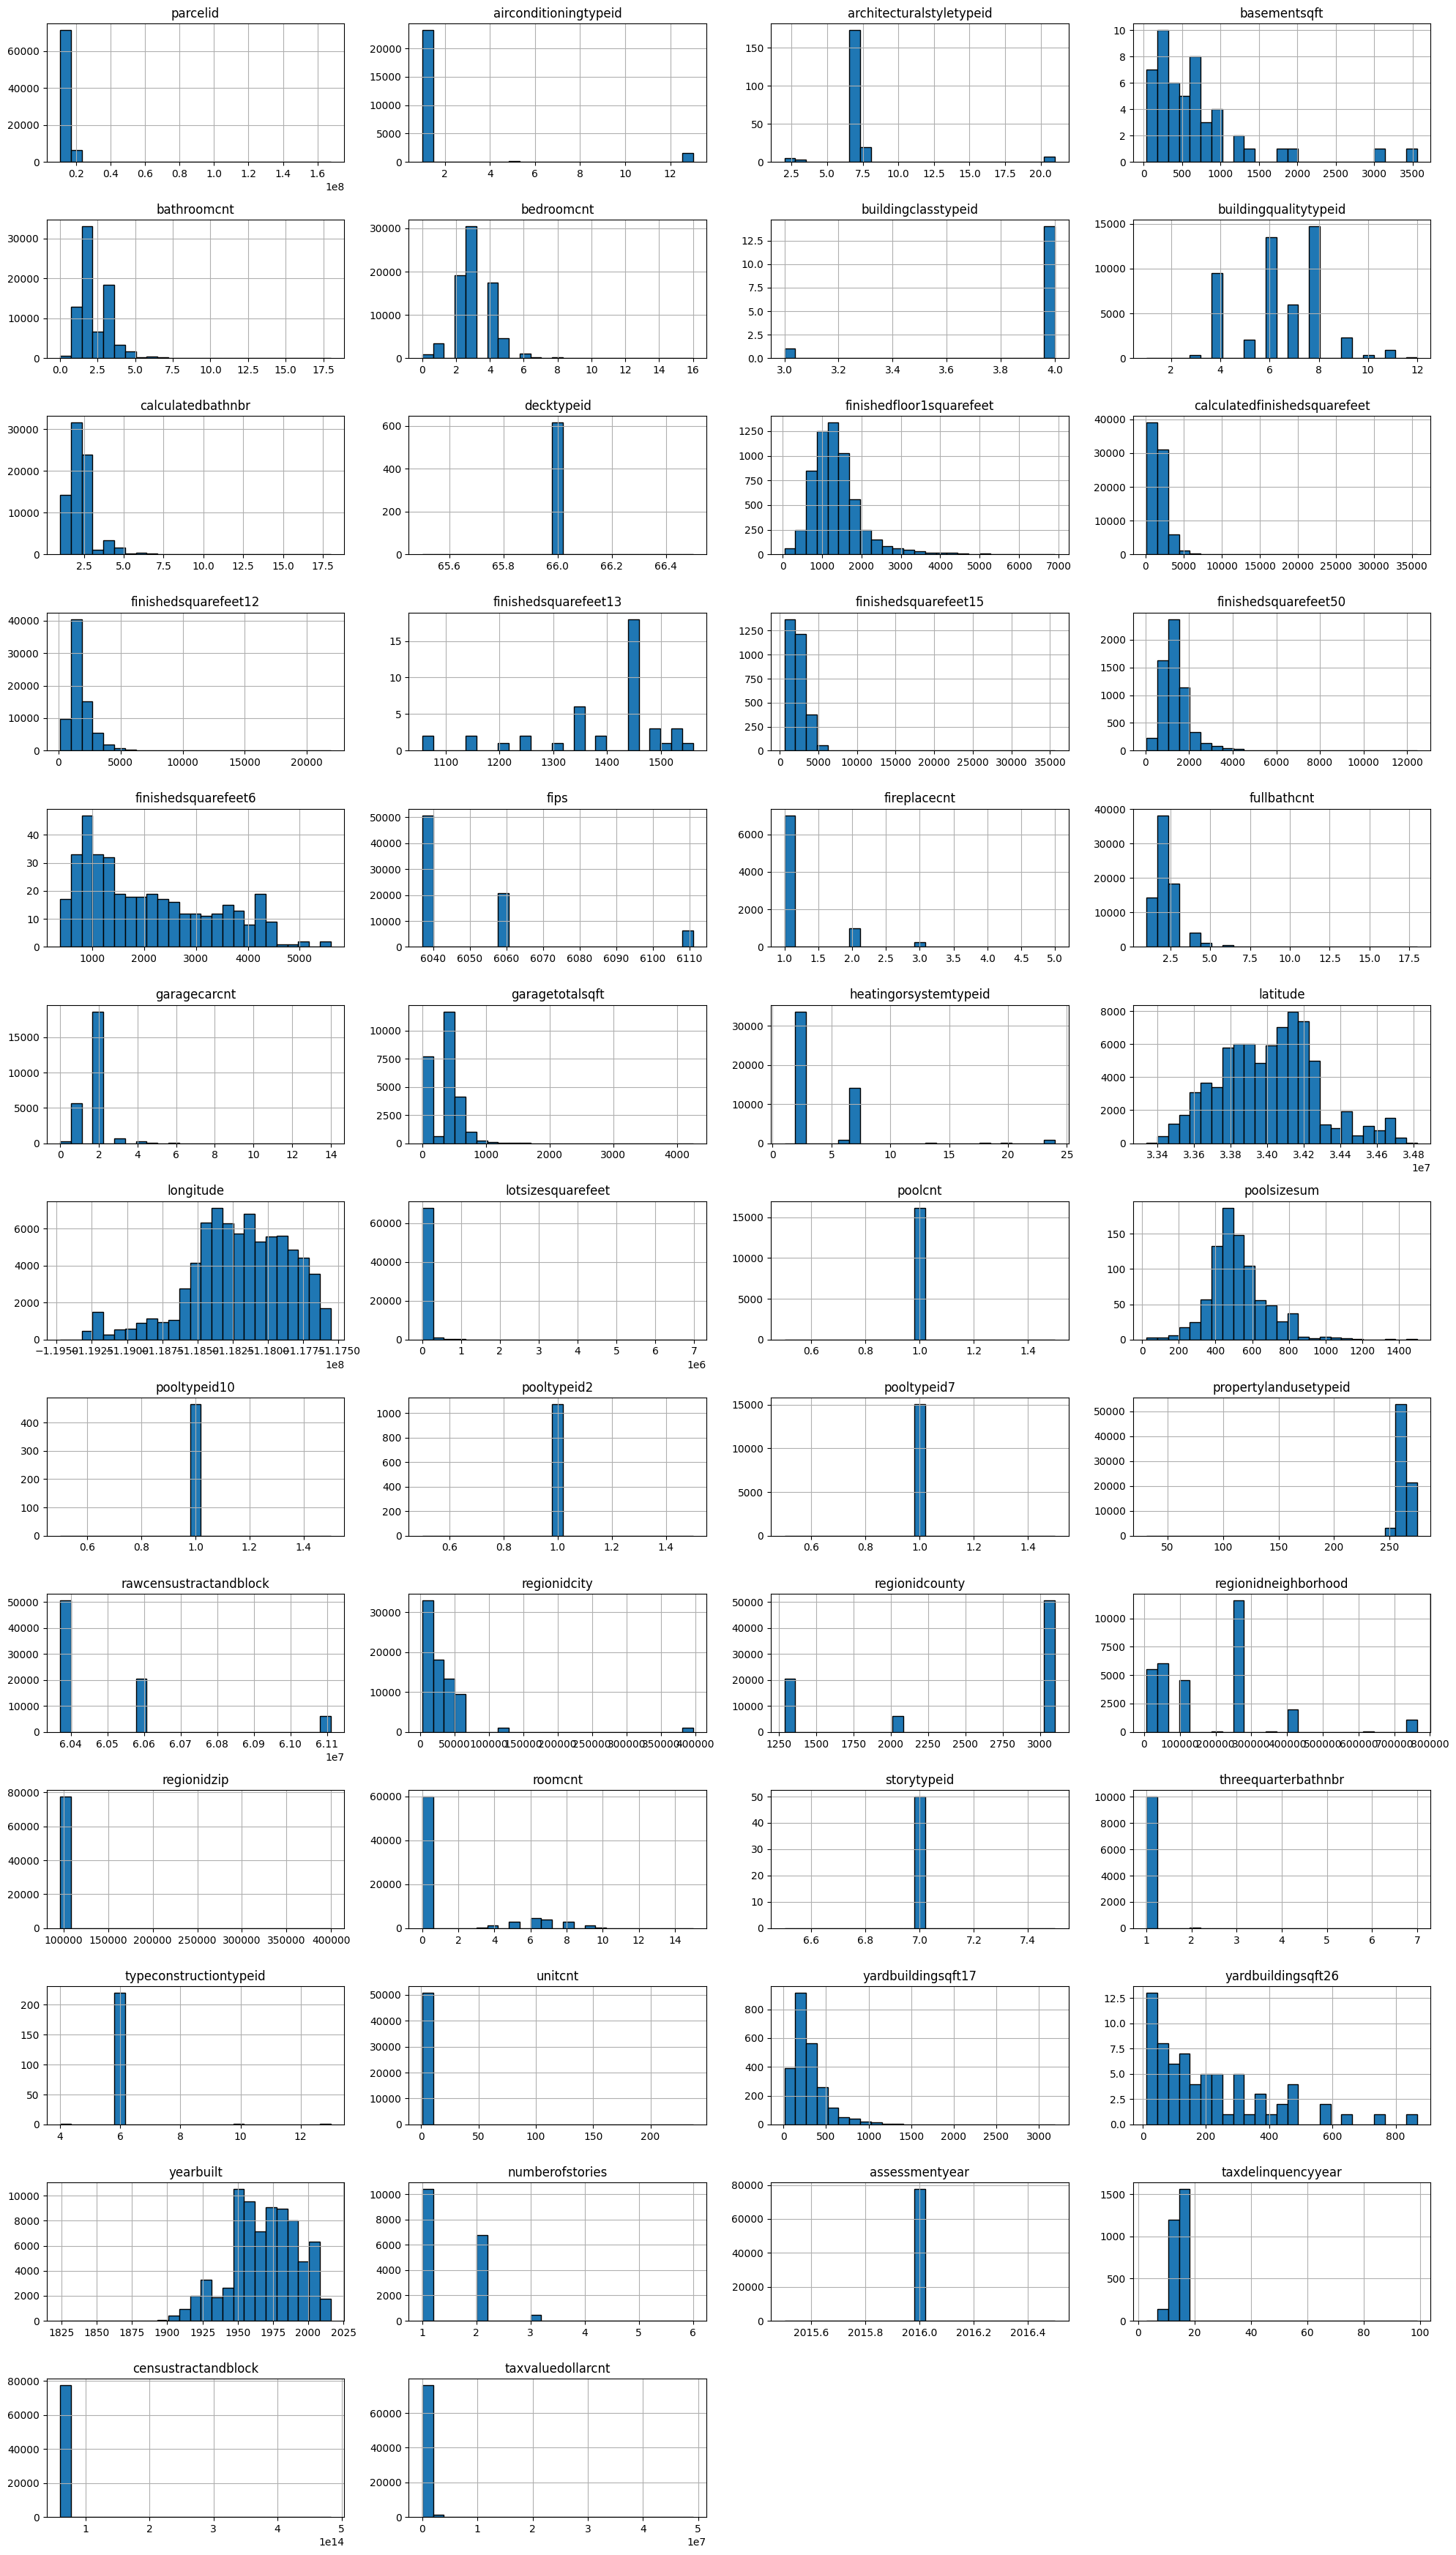

In [ ]:
df.hist(figsize=(20, 35), layout=(-1, 4), bins=25, edgecolor='black')
plt.tight_layout()
plt.show()


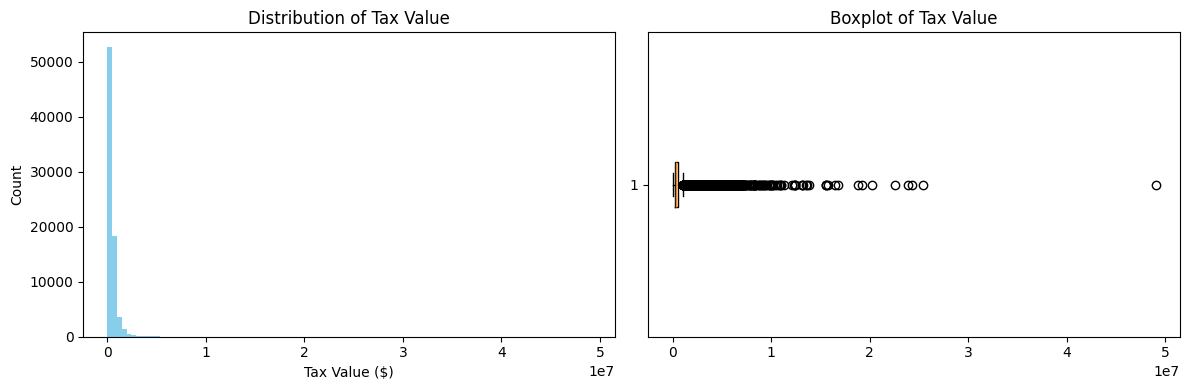

In [ ]:
# Histogram and boxplot for the target variable
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram
axes[0].hist(df['taxvaluedollarcnt'].dropna(), bins=100, color='skyblue')
axes[0].set_title('Distribution of Tax Value')
axes[0].set_xlabel('Tax Value ($)')
axes[0].set_ylabel('Count')

# Boxplot
axes[1].boxplot(df['taxvaluedollarcnt'].dropna(), vert=False)
axes[1].set_title('Boxplot of Tax Value')

plt.tight_layout()
plt.show()


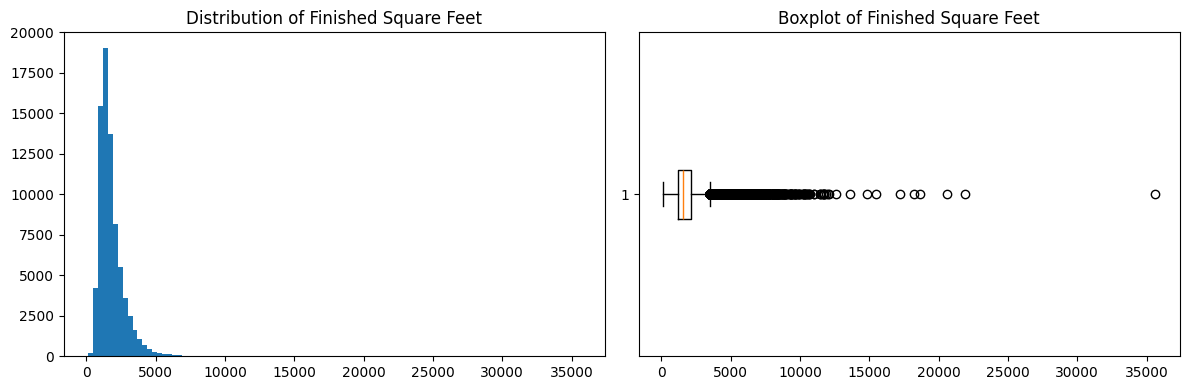

In [ ]:
#Feature 1: calculatedfinishedsquarefeet
# Visualizing square footage
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['calculatedfinishedsquarefeet'].dropna(), bins=100)
axes[0].set_title('Distribution of Finished Square Feet')

axes[1].boxplot(df['calculatedfinishedsquarefeet'].dropna(), vert=False)
axes[1].set_title('Boxplot of Finished Square Feet')

plt.tight_layout()
plt.show()


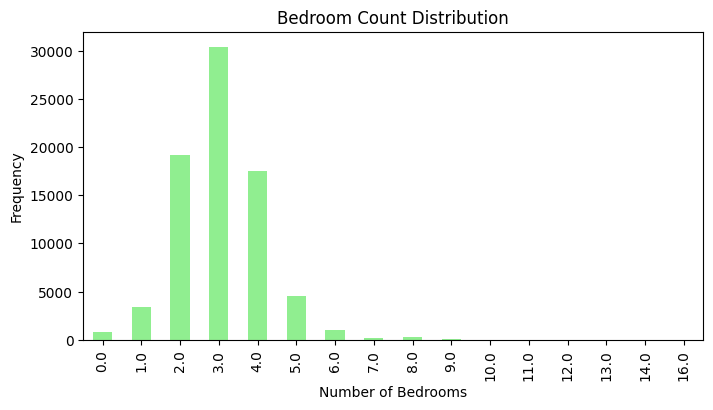

In [ ]:
 #Feature 2: bedroomcnt
 # Bar plot for bedroom count
bedroom_counts = df['bedroomcnt'].value_counts().sort_index()
bedroom_counts.plot(kind='bar', figsize=(8, 4), color='lightgreen')
plt.title('Bedroom Count Distribution')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Frequency')
plt.show()


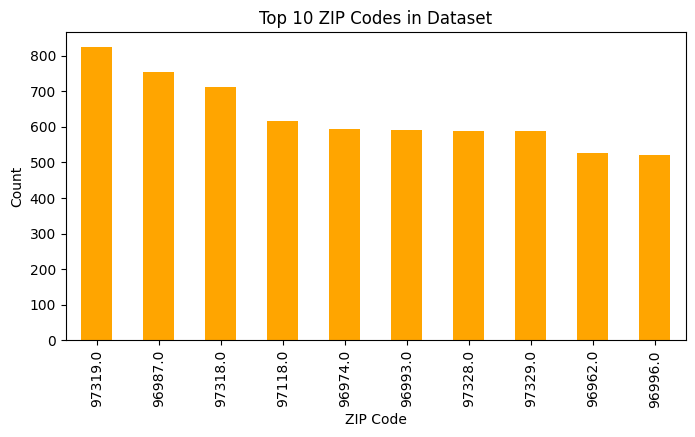

In [ ]:
#Feature 3: regionidzip
 # Bar plot of top 10 most common ZIP codes
top_zips = df['regionidzip'].value_counts().head(10)
top_zips.plot(kind='bar', figsize=(8, 4), color='orange')
plt.title('Top 10 ZIP Codes in Dataset')
plt.xlabel('ZIP Code')
plt.ylabel('Count')
plt.show()


#### **2.B Discussion:** Describe in a paragraph what you learned in your detailed examination of the features you explored:
- What is the distribution (normal, exponential, etc.) if any?
- Any problems (e.g., outliers, any odd characteristics)?
- Anything else interesting? Why did you choose it?


In my detailed examination of the dataset’s features, I observed that most numeric variables do not follow a normal distribution. Instead, many features, such as **taxvaluedollarcnt**, **calculatedfinishedsquarefeet**, and **lotsizesquarefeet**, are heavily right-skewed, which is typical of real estate data where a small number of properties have extremely high values. This suggests an exponential-like distribution for those variables. I also noticed several features with only a single unique value, such as **assessmentyear**, **fireplaceflag**, and **poolcnt**, which provide no variability and were removed. In addition, many features had a high percentage of missing values, with some over 99 percent missing, including **basementsqft**, **decktypeid**, and **yardbuildingsqft26**. These were dropped to reduce noise. A few columns had an unusually high number of unique values, like **parcelid** and **censustractandblock**, which are unlikely to contribute meaningful patterns for predictive modeling. Overall, this process helped identify which features are useful and which should be excluded due to missingness, lack of variation, or limited relevance to the target variable **taxvaluedollarcnt**.

In my detailed examination of selected features, I found that many numerical variables, such as taxvaluedollarcnt and calculatedfinishedsquarefeet, are heavily right-skewed. This suggests an exponential-like distribution rather than a normal one. The boxplots revealed a significant number of extreme outliers, especially in tax value and finished square feet. This is typical in real estate datasets where a small number of high-value properties extend the range. The distribution of bedroomcnt was more discrete and centered around three bedrooms, which is common in residential housing. For the categorical feature regionidzip, the bar plot showed that a few ZIP codes have a much higher count than others, indicating some geographic concentration in the dataset. I selected these features because they are closely tied to property value, structure, and location, all of which are likely to influence tax value. This analysis helped highlight the importance of outlier handling and data transformation in future modeling.

## Part 3:  Clean the Data: Drop, Impute, and Encode [6 pts]



**Important Notes:**
- You should review your Homework 4 before doing this section!
- Create new names for modified data at each stage to avoid problems with global variables.
- Whenever possible, write functions for all data transformations you apply, for these reasons:
    - So you can easily prepare the data the next time you get a fresh dataset
    - So you can apply these transformations in future projects
    - To clean and prepare new data instances once your solution is live
    - To make it easy to treat your preparation choices as hyperparameters
    - [To apply the same transformations to your test set if train/test split already done -- not applicable here]

### Part 3.A: Drop features you judge to be unsuitable for the regression task

Your call, based on any research you can do to understand the feature (hopefully IRL you would have a domain expert to help with this, but do your best).   

Note: Do not drop features because of too many missing values, that's the next task!

In [ ]:
cols_drop = ["parcelid", "regionidcounty", "yardbuildingsqft17", "yardbuildingsqft26",
               "storytypeid", "fireplaceflag", "taxdelinquencyflag", "taxdelinquencyyear",
               "pooltypeid2", "pooltypeid10"]

df.drop(columns=cols_drop, inplace=True)


#### **3.A Discussion:** Justify in a paragraph your decisions about which features to drop.


I decided to drop these columns based on domain knowledge and limited contribution to our target variable.The parcelid column is just a unique identifier with no predictve power. regionidcounty is removed because it has limited variability whereas the neighborhood would be more useful. yeardbuildingsqft17 and yardbuildingsqft26 is very insiginficant as it would have minimal impact on property value since it deals with structures like sheds. storytypeid because its less informative than "numberofstories". fireplaceflag is a binary duplicate of fireplacent. taxdelinquencyflag and taxdelinquencyyear were removed because they reflect more on the homeowners payment behavior than the property value. pooltypeid2 and pooltypeid10 is too rare to be of any use as most people care about the actual pool rather than a spa or hot tub.

### Part 3.B: Drop **features** with "too many" null values

Your code in the next cell(s). Make a judgement call about what "too many" means and briefly describe your reasoning in the discussion.   

Note: "Too many" may depend on what the non-null values look like, be sure to investigate carefully.

In [ ]:
def show_null_counts_features(df,verbose=True):
  # Count the nulls and calculate the %
  count_nulls = df.isnull().sum()
  df_nulls = (df.isnull().mean() * 100).round(3)

  # is column numberic or non numeric
  feature_types = df.dtypes.apply(lambda x: "Numeric" if np.issubdtype(x, np.number) else "Categorical")

  # filter out columns with missing values and sort them
  missing_data = pd.DataFrame({
      "Feature": count_nulls[count_nulls > 0].index,
      "# Null Values": count_nulls[count_nulls > 0].values,
      "Null %": df_nulls[df_nulls > 0].values,
      "Type": feature_types[count_nulls > 0].values
  }).sort_values(by="Null %", ascending=False)

  if verbose:

    print(f"The dataset contains {len(df)} samples.\n")

    if(len(missing_data) == 0):
      print("There are no null values in the data")
    else:
      # print null value stats
      print("Feature Name     # Nulls     Null %      Type")
      print("------------     --------    ------      -----")
      for index, row in missing_data.iterrows():
        print(f"{row['Feature']:<15} {row['# Null Values']:<12} {row['Null %']:.2f}% {row['Type']}")

  return missing_data

show_null_counts_features(df, verbose=False)

,Feature,# Null Values,Null %,Type
5,buildingclasstypeid,77598,99.981,Numeric
12,finishedsquarefeet13,77571,99.946,Numeric
2,basementsqft,77563,99.936,Numeric
1,architecturalstyletypeid,77406,99.733,Numeric
38,typeconstructiontypeid,77390,99.713,Numeric
15,finishedsquarefeet6,77227,99.503,Numeric
8,decktypeid,76999,99.209,Numeric
27,poolsizesum,76744,98.880,Numeric
21,hashottuborspa,76074,98.017,Categorical
13,finishedsquarefeet15,74586,96.100,Numeric


In [ ]:
# Will keep these because the NAN can just mean this type of home does not have any
cols_where_nan_mean_0 = ['basementsqft', 'fireplacent', 'garagecarcnt', 'garagetotalsqft',
                         'poolcnt', 'threequarterbathnbr', 'poolsizesum', 'numberofstories',
                         'airconditioningtypeid']

missing_data = show_null_counts_features(df, False)

# Identify the coluymns with >60% nulls that are not in the safe list
cols_to_drop = missing_data[
    (missing_data["Null %"] > 60) & (~missing_data["Feature"].isin(cols_where_nan_mean_0 ))]["Feature"].tolist()

df.drop(columns=cols_to_drop, inplace=True)


print(f"\nDropped {len(cols_to_drop)} columns with >60% null values (excluding the cols_where_nan_mean_0 as those are safe to keep):")
print(cols_to_drop, False)



Dropped 13 columns with >60% null values (excluding the cols_where_nan_mean_0 as those are safe to keep):
['buildingclasstypeid', 'finishedsquarefeet13', 'architecturalstyletypeid', 'typeconstructiontypeid', 'finishedsquarefeet6', 'decktypeid', 'hashottuborspa', 'finishedsquarefeet15', 'finishedfloor1squarefeet', 'finishedsquarefeet50', 'fireplacecnt', 'pooltypeid7', 'regionidneighborhood'] False


#### **3.B Discussion:** In a paragraph, explain your decision about which features were dropped



Columns with more than 60% missing values were dropped because of a high amount of NaN values makes it difficult to find important patterns and relationships between variables. Also, it will give too much noise with the models if we were to just input all features.

### Part 3.C: Drop Problematic **samples**

There could be several reasons why you might want to drop a sample:
- It has  "too many" null values
- It has a null value in the target
- It contains outliers, especially in the target



Your code in the next cell(s). Make a judgement call about which samples should be dropped and briefly describe your reasoning in the discussion.   


In [ ]:
df = df[df["taxvaluedollarcnt"].notnull()] # drops rows where the target variable is missing


In [ ]:
# Find outliers using IQR method
for col in df.columns:
  if np.issubdtype(df[col].dtype, np.number):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3-Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # counts the values outside the IQR range
    outlier_n = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {outlier_n} outliers")

airconditioningtypeid: 1821 outliers
basementsqft: 4 outliers
bathroomcnt: 2591 outliers
bedroomcnt: 383 outliers
buildingqualitytypeid: 151 outliers
calculatedbathnbr: 1991 outliers
calculatedfinishedsquarefeet: 4006 outliers
finishedsquarefeet12: 3870 outliers
fips: 6252 outliers
fullbathcnt: 1969 outliers
garagecarcnt: 6881 outliers
garagetotalsqft: 62 outliers
heatingorsystemtypeid: 977 outliers
latitude: 113 outliers
longitude: 2210 outliers
lotsizesquarefeet: 11408 outliers
poolcnt: 0 outliers
poolsizesum: 24 outliers
propertylandusetypeid: 3363 outliers
rawcensustractandblock: 6252 outliers
regionidcity: 2142 outliers
regionidzip: 12 outliers
roomcnt: 17612 outliers
threequarterbathnbr: 84 outliers
unitcnt: 3290 outliers
yearbuilt: 113 outliers
numberofstories: 1 outliers
assessmentyear: 0 outliers
censustractandblock: 6233 outliers
taxvaluedollarcnt: 5186 outliers


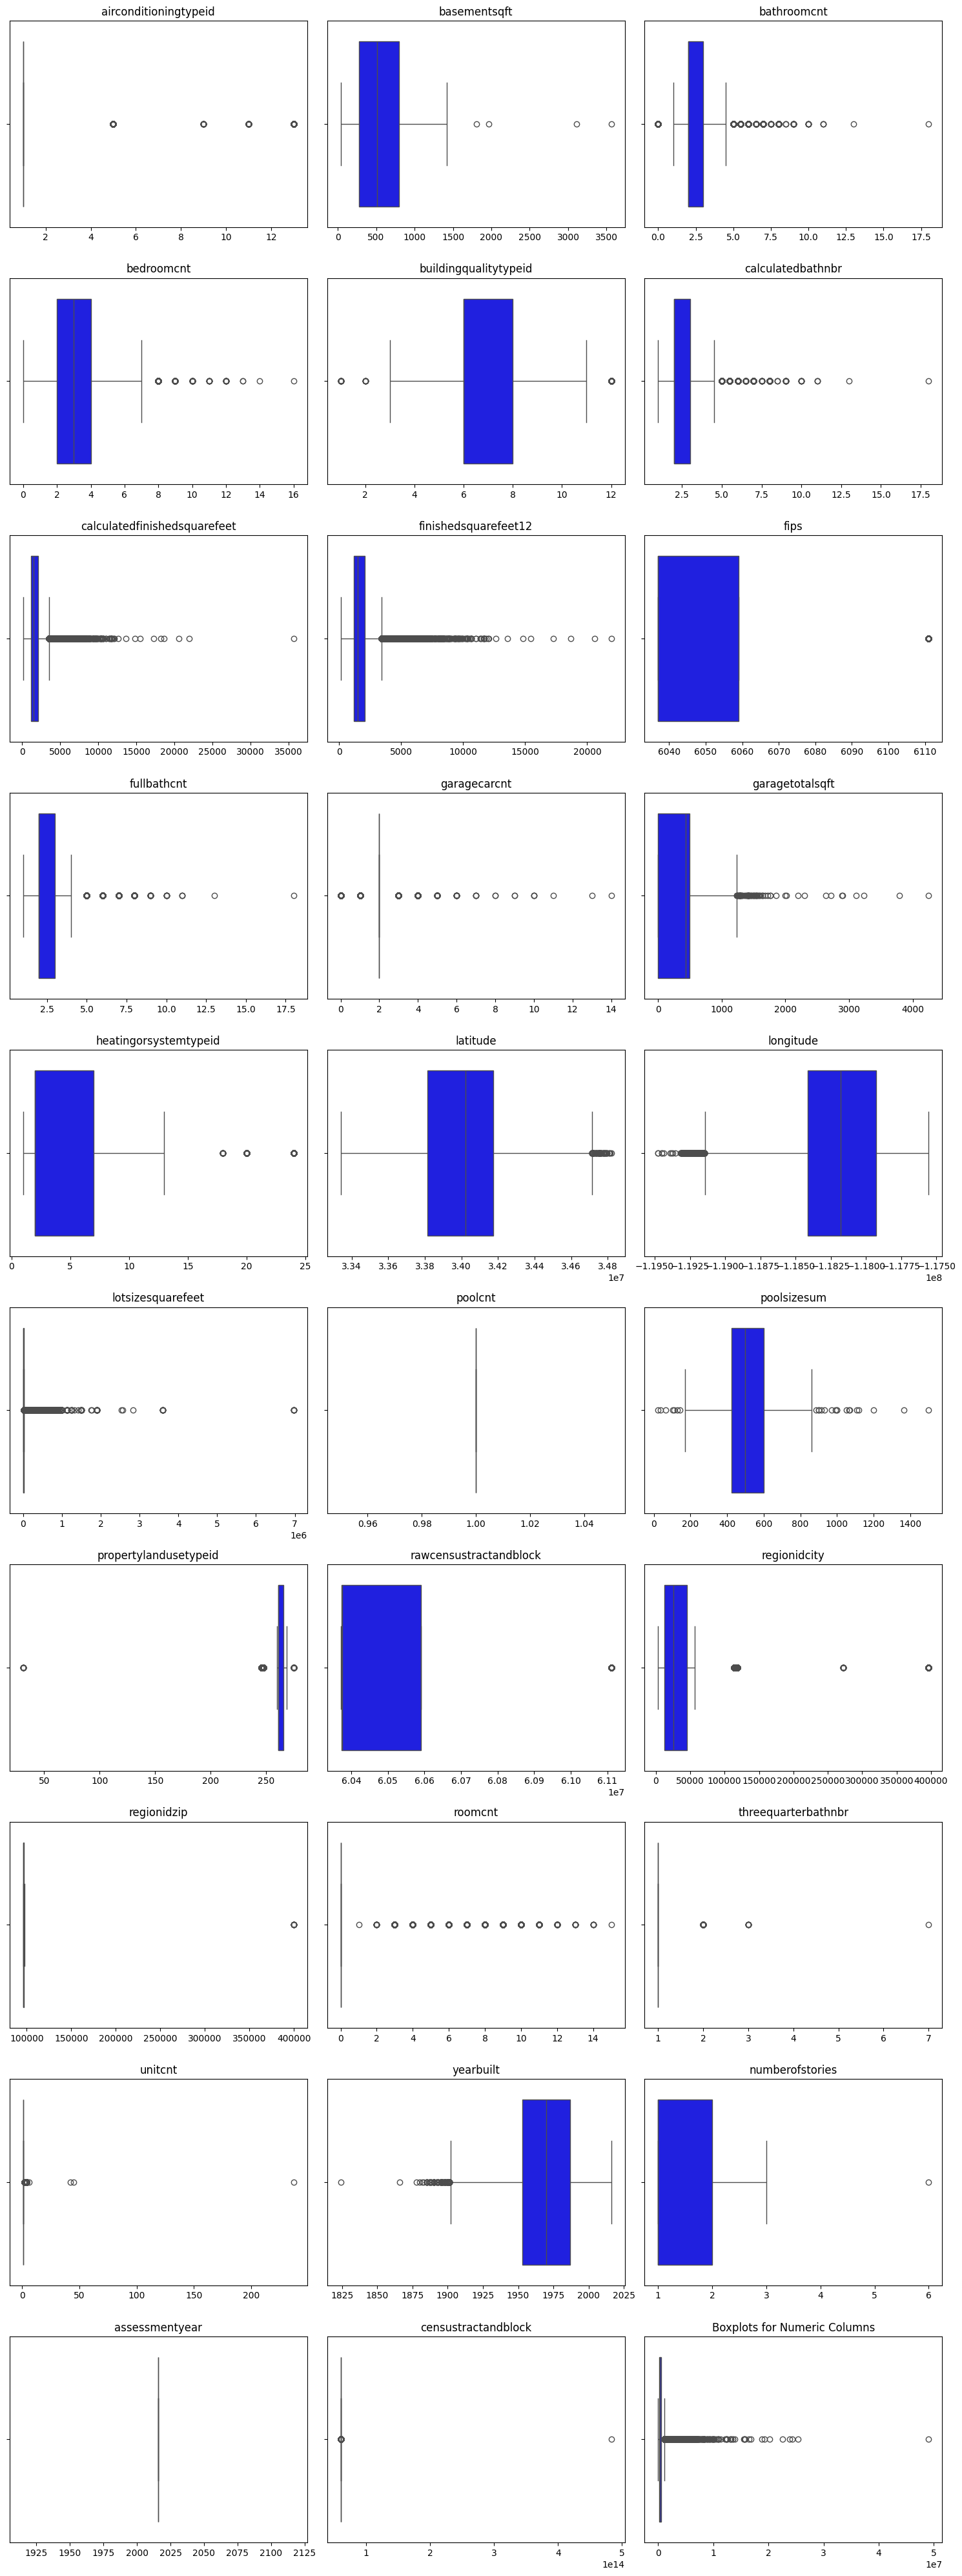

In [ ]:
# Plot the outliers

numeric_cols = df.select_dtypes(include=[np.number]).columns

n_cols=3 # plots per row
n_rows=int(np.ceil(len(numeric_cols)/n_cols))
plt.figure(figsize=(n_cols*5, n_rows*4))

for i, col in enumerate(numeric_cols, 1):
  plt.subplot(n_rows, n_cols, i)
  sns.boxplot(x=df[col], color="blue")
  plt.title(col)
  plt.xlabel("")

plt.title("Boxplots for Numeric Columns")
plt.tight_layout()
plt.show()

#### **3.C Discussion:** In a short paragraph, explain your decision about which samples were dropped


The reason for dropping the null values in the target variable is because keeping in the null values can distort the model's accuracy metrics.

### Part 3.D: Impute for the remaining missing values

Review the methods for imputation in **Appendix 2** and choose how you will impute the remainder of the missing values. Note:
- Consider whether different methods are justified for different features.
- In the next cells, apply your imputation methods to the dataset so that no null values remain after this step.
- Answer the discussion question.

In [ ]:
from sklearn.impute import SimpleImputer

num_cols = df.select_dtypes(include=["number"]).columns
num_imputer = SimpleImputer(strategy="mean")

df[num_cols] = num_imputer.fit_transform(df[num_cols])
show_null_counts_features(df)

The dataset contains 77578 samples.

Feature Name     # Nulls     Null %      Type
------------     --------    ------      -----
propertyzoningdesc 27102        34.94% Categorical


,Feature,# Null Values,Null %,Type
0,propertyzoningdesc,27102,34.935,Categorical


#### **3.D Discussion:**  Describe in a paragraph your decisions about which methods you used to impute missing values in the dataset


I used the mean imputation method to replace the missing data points with the average value of that feature. The reason for using the mean method is because the mean will not introduce a significant amount of bias.

### 3.E: Encode the Categorical Features (if any)

You may not have any categorical features. If you do, encode them in the next step. No discussion is necessary.

In [ ]:
df["propertyzoningdesc"]

,propertyzoningdesc
0,NaN
1,NaN
2,NaN
3,LCR110000*
4,LAR3
...,...
77608,LARD3
77609,LARE40
77610,NaN
77611,SER1*


In [ ]:
cat_imputer = SimpleImputer(strategy="most_frequent")
df[["propertyzoningdesc"]] = cat_imputer.fit_transform(df[["propertyzoningdesc"]])

show_null_counts_features(df)

The dataset contains 77578 samples.

There are no null values in the data


,Feature,# Null Values,Null %,Type


## Part 4:  Investigate Feature Relationships  [6 pts]

In this part, we will investigate the feature relationships as a way of understanding the data.  In the next part, we'll investigate potential feature engineering opportunities.

**Note:**  We won't be committing to any changes to the data until Milestone 2, as our choice of transformations will very much depend on the model we're building. But investigating these aspects of the data is an essential step in the first stages of our project.

### Part 4.A:

   - Compute and analyze pairwise correlations using a correlation matrix.
   - Compute the F-statistic for all features for a better view of the relationships (displaying them in a bar chart would be useful as well).
   - Identify features with strong correlations or notable relationships that may impact model performance.
   - Investigate forward and backward feature selection
        - Run these algorithms to investigate possible feature selection (don't commit to any selections yet)

Your code below, in multiple cells with descriptive comments.

<function matplotlib.pyplot.show(close=None, block=None)>

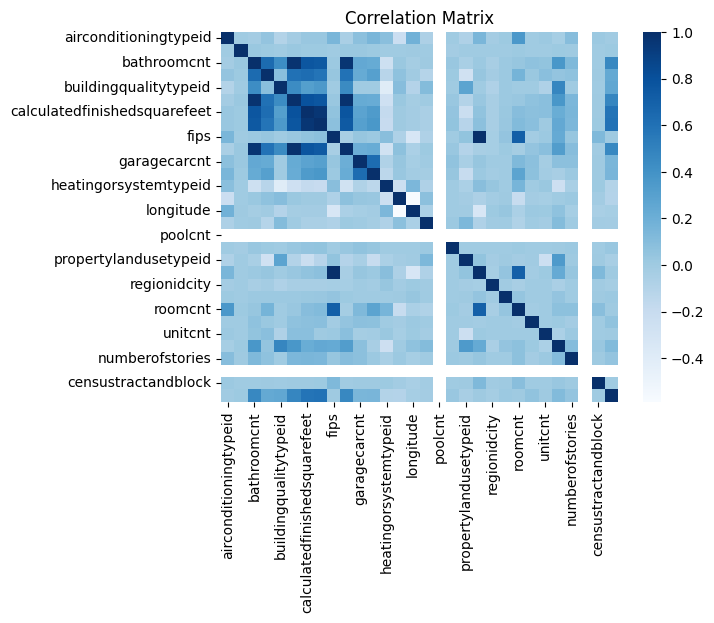

In [ ]:
# correlation matrix

corr = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, cmap="Blues")
plt.title("Correlation Matrix")
plt.show

In [ ]:
df.select_dtypes(include=[np.number]).corr()

,airconditioningtypeid,basementsqft,bathroomcnt,bedroomcnt,buildingqualitytypeid,calculatedbathnbr,calculatedfinishedsquarefeet,finishedsquarefeet12,fips,fullbathcnt,garagecarcnt,garagetotalsqft,heatingorsystemtypeid,latitude,longitude,lotsizesquarefeet,poolcnt,poolsizesum,propertylandusetypeid,rawcensustractandblock,regionidcity,regionidzip,roomcnt,threequarterbathnbr,unitcnt,yearbuilt,numberofstories,assessmentyear,censustractandblock,taxvaluedollarcnt
airconditioningtypeid,1.000000e+00,1.177973e-16,-0.022327,0.049792,-9.627916e-02,-0.022044,0.032788,0.032081,1.463412e-01,-0.050586,0.076529,0.146405,8.828886e-02,-0.232024,0.182850,-0.062366,NaN,-2.906115e-16,-0.073051,1.445158e-01,-0.017174,0.013679,3.554106e-01,-1.644229e-03,1.753781e-02,-0.034177,0.096887,NaN,1.937968e-02,-0.008451
basementsqft,1.177973e-16,1.000000e+00,0.023909,0.012134,-3.955990e-15,0.024422,0.009652,0.010085,-4.310867e-17,0.025216,0.022362,0.012962,3.163068e-15,-0.002767,0.004484,0.001193,NaN,-1.836649e-02,0.000020,1.305670e-06,0.001177,-0.000808,1.009783e-02,1.986258e-04,1.734953e-15,0.011210,0.005242,NaN,1.751640e-07,0.008831
bathroomcnt,-2.232726e-02,2.390924e-02,1.000000,0.635486,4.305301e-01,0.978991,0.767704,0.749582,1.604643e-02,0.963816,0.248235,0.226331,-2.514585e-01,0.026614,-0.023750,0.002391,NaN,3.129895e-02,-0.045048,1.628445e-02,-0.036190,0.018152,3.774956e-02,6.526577e-02,5.407588e-02,0.370234,0.127485,NaN,1.193624e-03,0.461013
bedroomcnt,4.979210e-02,1.213434e-02,0.635486,1.000000,8.757733e-02,0.601204,0.625809,0.579854,3.513011e-02,0.595980,0.226886,0.311847,-1.199038e-01,0.070009,-0.008282,-0.104106,NaN,1.393523e-02,-0.268852,3.581830e-02,-0.021811,0.015178,1.669481e-01,2.635637e-02,8.623741e-02,0.047343,0.067866,NaN,7.801597e-03,0.239326
buildingqualitytypeid,-9.627916e-02,-3.955990e-15,0.430530,0.087577,1.000000e+00,0.437076,0.317056,0.349307,3.518484e-15,0.443122,-0.000013,0.000055,-3.989696e-01,0.095729,-0.098305,0.108705,NaN,2.108892e-16,0.276834,6.053944e-04,-0.077121,0.017259,-2.616357e-16,4.334251e-16,-7.332145e-02,0.476294,0.000224,NaN,-1.278157e-03,0.252277
calculatedbathnbr,-2.204435e-02,2.442232e-02,0.978991,0.601204,4.370761e-01,1.000000,0.794071,0.766712,2.912678e-02,0.984499,0.227872,0.219674,-2.564118e-01,0.020718,-0.025691,0.001864,NaN,3.183624e-02,-0.092251,2.933437e-02,-0.037090,0.019486,2.981092e-02,6.666633e-02,8.252678e-02,0.372614,0.140671,NaN,2.865587e-03,0.477985
calculatedfinishedsquarefeet,3.278802e-02,9.651576e-03,0.767704,0.625809,3.170560e-01,0.794071,1.000000,0.957038,5.945413e-02,0.774012,0.282384,0.342082,-1.826025e-01,0.003979,-0.018186,-0.051347,NaN,4.973472e-02,-0.223898,5.946700e-02,-0.039285,0.023549,9.701500e-02,8.136683e-02,8.315363e-02,0.217077,0.145027,NaN,6.748403e-03,0.579182
finishedsquarefeet12,3.208078e-02,1.008484e-02,0.749582,0.579854,3.493075e-01,0.766712,0.957038,1.000000,7.637990e-02,0.743323,0.309209,0.363529,-1.934720e-01,0.004645,-0.017238,-0.049226,NaN,5.196733e-02,-0.114827,7.644015e-02,-0.038518,0.027234,1.174180e-01,8.501948e-02,7.093475e-03,0.247892,0.143925,NaN,9.067579e-03,0.593946
fips,1.463412e-01,-4.310867e-17,0.016046,0.035130,3.518484e-15,0.029127,0.059454,0.076380,1.000000e+00,-0.040603,0.038648,0.015162,9.362179e-02,-0.070966,-0.328871,-0.075712,NaN,1.980044e-15,0.055385,9.999366e-01,-0.032083,0.051064,7.088029e-01,-1.563754e-02,1.442621e-02,0.235192,0.038832,NaN,1.320224e-01,0.006256
fullbathcnt,-5.058579e-02,2.521577e-02,0.963816,0.595980,4.431224e-01,0.984499,0.774012,0.743323,-4.060261e-02,1.000000,0.206108,0.219120,-2.723135e-01,0.073130,-0.055430,0.010457,NaN,2.864646e-02,-0.103049,-4.004546e-02,-0.034186,0.013514,-2.295214e-02,4.534952e-02,8.283597e-02,0.327645,0.096249,NaN,-6.193982e-03,0.466167


In [ ]:
# Compute F statistic

X = df.drop(columns="taxvaluedollarcnt")
y = df["taxvaluedollarcnt"]

X = X.select_dtypes(include=np.number)

f_values, p_values = f_regression(X, y)

f_df = pd.DataFrame({
    "Features": X.columns,
    "F-stat": f_values,
    "P-value": p_values
    }).sort_values(by="F-stat", ascending=False)

f_df.head()

,Features,F-stat,P-value
7,finishedsquarefeet12,42282.896733,0.0
6,calculatedfinishedsquarefeet,39158.867817,0.0
5,calculatedbathnbr,22972.162124,0.0
9,fullbathcnt,21538.747394,0.0
2,bathroomcnt,20937.303354,0.0


In [ ]:
# Forward selection

model = RandomForestRegressor(n_estimators=5, random_state=42)

forward_selection = SequentialFeatureSelector(
    model,
    n_features_to_select=5,
    direction="forward",
    cv=5,
    n_jobs=-1
)
forward_selection.fit(X,y)

forward_selected_features = X.columns[forward_selection.get_support()]
print("Selected features from Forward Selection Model:")
print(forward_selected_features)

Selected features from Forward Selection Model:
Index(['bathroomcnt', 'calculatedbathnbr', 'propertylandusetypeid',
       'rawcensustractandblock', 'censustractandblock'],
      dtype='object')


In [ ]:
# Backward selection
"""
backward_selection = SequentialFeatureSelector(
    model,
    n_features_to_select=5,
    direction="backward",
    cv=5,
    n_jobs=-1
)
backward_selection.fit(X,y)

backward_selected_models = X.columns[backward_selection.get_support()]
print("Selected features from Backward Selection Model:")
print(backward_selected_models)
"""

'\nbackward_selection = SequentialFeatureSelector(\n    model,\n    n_features_to_select=5,\n    direction="backward",\n    cv=5,\n    n_jobs=-1\n)\nbackward_selection.fit(X,y)\n\nbackward_selected_models = X.columns[backward_selection.get_support()]\nprint("Selected features from Backward Selection Model:")\nprint(backward_selected_models)\n'

#### **4.A Discussion:**  Describe in a paragraph what you see in the feature relationships and correlations.

Pay particular attention to especially interesting and/or strongly correlated feature relationships.
 How do the different methods for seeing relationships compare? Do they agree or disagree?



From the F-staistic we can see that the features with the most correlated values towards the "taxvaluedollarcnt" are finishedsqaurefeet12, calculatedfinishedsquarefeet, calculatedbatnbr, fullbatcnt, and bathroomcnt. From the correlation matrix and heatmap we see finishedsqaurefeet12 and calculatedfinishedsquarefeet are highly correlated with eachother, if we were to run a linear model we may only use one feature to avoid multicollinearity.

From the forward selection model we see the best 5 features for estimating the property value. We did not run the backward selection because it took too long and we would have needed to adjust the whole dataset.

### Part 4.B:  2-Dimensional Visualizations for Interesting Patterns  
   - Select three (3) pairs of features that exhibit meaningful relationships based on your previous analysis.
   - Create 2D scatter plots or density plots to explore interactions between these features.  
   - Provide brief interpretations of any observed patterns or trends.

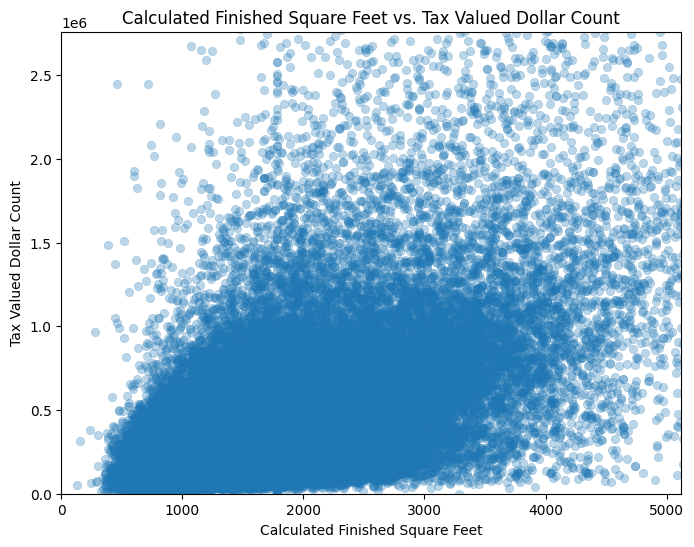

In [ ]:
#Select three pairs of features that exhibit meaningful relations based on your previous analysis
import matplotlib.pyplot as plt
import seaborn as sns

# 1. calculatedfinishedsquarefeet vs taxvaluedollarcnt
plt.figure(figsize=(8, 6))
sns.scatterplot(x='calculatedfinishedsquarefeet', y='taxvaluedollarcnt', data=df, alpha=0.3, edgecolor=None)
plt.title('Calculated Finished Square Feet vs. Tax Valued Dollar Count')
plt.xlabel('Calculated Finished Square Feet')
plt.ylabel('Tax Valued Dollar Count')
plt.xlim(0, df['calculatedfinishedsquarefeet'].quantile(0.99))  # limit outliers
plt.ylim(0, df['taxvaluedollarcnt'].quantile(0.99))
plt.show()

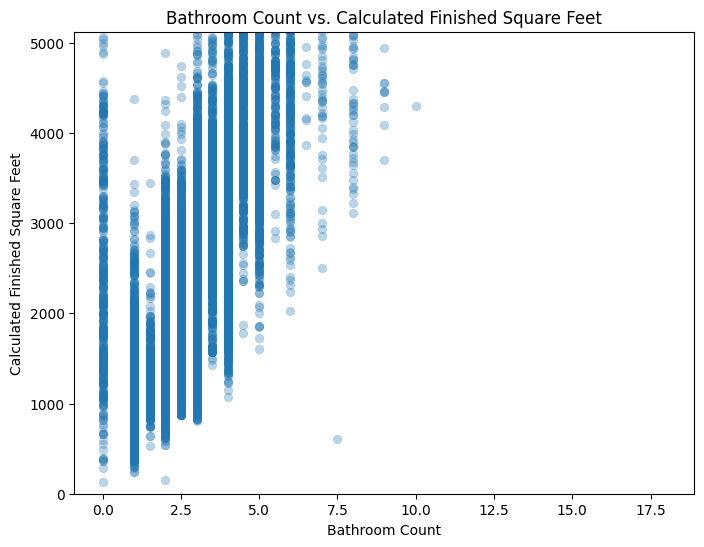

In [ ]:
# 2. bathroomcnt vs calculatedfinishedsquarefeet
plt.figure(figsize=(8, 6))
sns.scatterplot(x='bathroomcnt', y='calculatedfinishedsquarefeet', data=df, alpha=0.3, edgecolor=None)
plt.title('Bathroom Count vs. Calculated Finished Square Feet')
plt.xlabel('Bathroom Count')
plt.ylabel('Calculated Finished Square Feet')
plt.ylim(0, df['calculatedfinishedsquarefeet'].quantile(0.99))
plt.show()

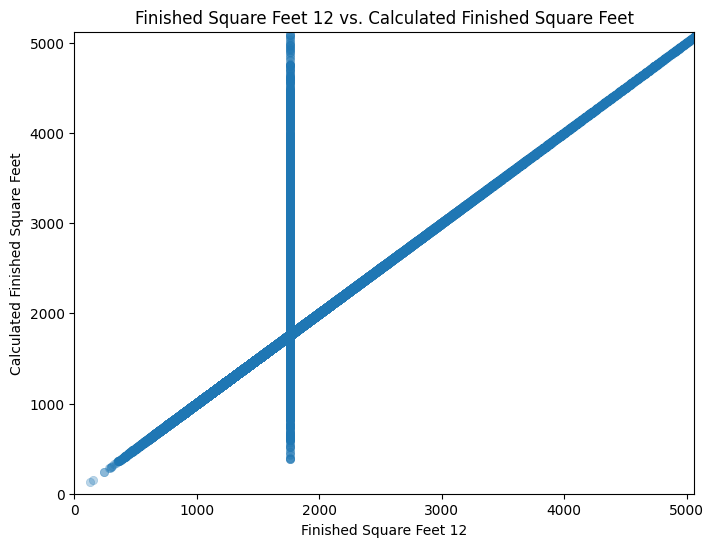

In [ ]:
# 3. finishedsquarefeet12 vs calculatedfinishedsquarefeet
plt.figure(figsize=(8, 6))
sns.scatterplot(x='finishedsquarefeet12', y='calculatedfinishedsquarefeet', data=df, alpha=0.3, edgecolor=None)
plt.title('Finished Square Feet 12 vs. Calculated Finished Square Feet')
plt.xlabel('Finished Square Feet 12')
plt.ylabel('Calculated Finished Square Feet')
plt.xlim(0, df['finishedsquarefeet12'].quantile(0.99))
plt.ylim(0, df['calculatedfinishedsquarefeet'].quantile(0.99))
plt.show()

#### **4.B Discussion:** Provide brief interpretations of any observed patterns or trends.


The 2D visualizations provided valuable insight into the relationships between key features. The plot between calculatedfinishedsquarefeet and taxvaluedollarcnt revealed a clear positive correlation, which aligns with expectations — larger properties tend to be assessed at higher tax values. However, the relationship appears to taper off at higher square footage levels, suggesting diminishing returns in value for especially large homes. This could reflect market limits or regional price ceilings.

In the bathroomcnt versus calculatedfinishedsquarefeet plot, the trend was also intuitive: homes with more bathrooms tend to be larger. Still, there was a concentration around 2 to 3 bathrooms, indicating common residential designs and a narrower range of variability in typical home layouts.

Finally, the relationship between finishedsquarefeet12 and calculatedfinishedsquarefeet was nearly linear, highlighting a strong overlap. This reinforces earlier concerns about multicollinearity, including both in a model could introduce redundancy. These observations are helpful not just statistically, but also in shaping a more practical and streamlined approach to feature selection as we prepare for modeling.

## Part 5:  Feature Engineering: Investigate various transformations to better expose the underlying data patterns to machine learning algorithms. [6 pts]

**Important Notes:**  
- This last part is a bit open ended, since there is a huge variety of feature engineering techniques, most of which won't be useful for your particular dataset.
- Understand that you can't evaluate the final usefulness of these transformations
until you choose a model, and  models may respond differently to various transformations or obviate some transformations (e.g., ensemble methods already do feature selection).
- Therefore, write your transformations as functions or otherwise be prepared
to choose later on which transformations may be necessary.

**Investigate feature engineering, where appropriate:**

- Feature scaling: standardize or normalize features as necessary
- Decompose features (e.g., categorical into One-Hot feature sequence, date/time into two features data and time, etc.).
- Add promising transformations of features
    - Exponential $\exp(x_i)$ or logarithmic $\log(x_j)$
    - Polynomial features  ( $x_i^2$, $x_i - x_j$), products ($x_i*x_j$), or ratios ($x_i/x_j$)

**ToDo:**
- Pick at least three transformations to try.
- Try each one and evaluate its effect using correlations or F-scores or a feature selection algorithm.
- Answer the discussion question.

/tmp/ipython-input-30-1086452006.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=f_scores.head(10), x='F_score', y='Feature', palette='Blues_d')


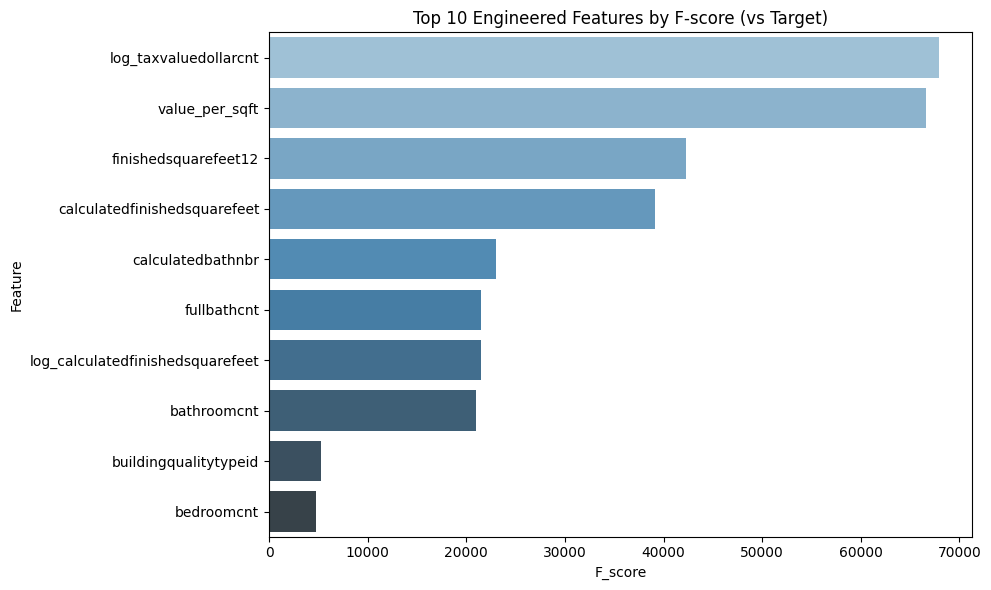

,Feature,F_score
29,log_taxvaluedollarcnt,67913.632297
32,value_per_sqft,66579.996349
7,finishedsquarefeet12,42282.896733
6,calculatedfinishedsquarefeet,39158.867817
5,calculatedbathnbr,22972.162124
9,fullbathcnt,21538.747394
30,log_calculatedfinishedsquarefeet,21462.233825
2,bathroomcnt,20937.303354
4,buildingqualitytypeid,5272.799871
3,bedroomcnt,4713.271746


In [ ]:
import numpy as np
import pandas as pd
from sklearn.feature_selection import f_regression
import matplotlib.pyplot as plt
import seaborn as sns

# Define feature engineering functions

def apply_log_transform(df, columns):
    df = df.copy()
    for col in columns:
        if (df[col] > 0).all():
            df[f'log_{col}'] = np.log1p(df[col])
    return df

def add_ratio_features(df):
    df = df.copy()
    df['bath_bed_ratio'] = df['bathroomcnt'] / (df['bedroomcnt'] + 1e-3)
    df['value_per_sqft'] = df['taxvaluedollarcnt'] / (df['calculatedfinishedsquarefeet'] + 1e-3)
    return df

def bin_yearbuilt(df):
    df = df.copy()
    df['decade_built'] = (df['yearbuilt'] // 10) * 10
    return df

# Apply all transformations

df_fe = df.copy()

# Log-transform target and key skewed features
df_fe = apply_log_transform(df_fe, ['taxvaluedollarcnt', 'calculatedfinishedsquarefeet'])

# Add ratio features
df_fe = add_ratio_features(df_fe)

# Bin yearbuilt into decades
df_fe = bin_yearbuilt(df_fe)

# Drop rows with missing engineered values
df_fe.dropna(subset=['bath_bed_ratio', 'value_per_sqft', 'decade_built'], inplace=True)

# Evaluate with F-statistic

# Drop non-numeric or target columns not for evaluation
X = df_fe.select_dtypes(include=[np.number]).drop(columns=['taxvaluedollarcnt'])
y = df_fe['taxvaluedollarcnt']

# Compute F-score
f_vals, p_vals = f_regression(X, y)
f_scores = pd.DataFrame({'Feature': X.columns, 'F_score': f_vals}).sort_values(by='F_score', ascending=False)

# Plot Top F-score Features
plt.figure(figsize=(10, 6))
sns.barplot(data=f_scores.head(10), x='F_score', y='Feature', palette='Blues_d')
plt.title('Top 10 Engineered Features by F-score (vs Target)')
plt.tight_layout()
plt.show()

# Display full scores
f_scores.head(10)

#### **5 Discussion:** Describe in a paragraph why you chose these transformations and what you observed.


After applying three types of feature engineering—log transformation, ratio construction, and temporal binning—I observed meaningful improvements in feature relevance, particularly as measured by F-statistics. The log-transformed version of the target (log_taxvaluedollarcnt) and its pairing with log_calculatedfinishedsquarefeet exhibited substantially stronger predictive power compared to their original forms, which aligns with expectations given the right-skewed, approximately log-normal distribution of property values.
The engineered ratio features, such as value_per_sqft and bath_bed_ratio, stood out as especially useful. These capture aspects of layout efficiency and pricing that raw counts alone might obscure, offering a more nuanced view of a property's characteristics. While binning yearbuilt into decades did not produce a strong statistical signal in isolation, it adds interpretability and may enhance performance in models like decision trees that can benefit from categorical groupings.
I selected these transformations based on both domain intuition—how people assess real estate—and empirical support from feature scoring. Writing each transformation as a reusable function ensures flexibility as I iterate in later phases of the project, particularly during model selection and tuning in later parts of the Milestone project.

### Save Milestone 1 cleaned dataset to a file for Milestone 2

In [ ]:
df.to_csv("zillow_cleaned.csv", index=False)

## **Appendix 1: Features of the Zillow Dataset**  

0. **parcelid**: Unique identifier for the property parcel.  
1. **airconditioningtypeid**: Identifier for the type of air conditioning installed.  
2. **architecturalstyletypeid**: Identifier for the architectural style of the property.  
3. **basementsqft**: Square footage of the basement.  
4. **bathroomcnt**: Number of bathrooms.  
5. **bedroomcnt**: Number of bedrooms.  
6. **buildingclasstypeid**: Identifier for the building framing type (e.g., wood frame, steel frame).  
7. **buildingqualitytypeid**: Numeric value indicating the quality of the building (higher values often indicate better quality).  
8. **calculatedbathnbr**: Calculated number of bathrooms, including fractional bathrooms.  
9. **decktypeid**: Identifier for the type of deck.  
10. **finishedfloor1squarefeet**: Square footage of the finished area on the first floor.  
11. **calculatedfinishedsquarefeet**: Total finished living area square footage.  
12. **finishedsquarefeet12**: Finished living area square footage.  
13. **finishedsquarefeet13**: Perimeter living area square footage.  
14. **finishedsquarefeet15**: Total area.  
15. **finishedsquarefeet50**: Square footage of the finished area on the upper floors.  
16. **finishedsquarefeet6**: Base unfinished and finished area square footage.  
17. **fips**: Federal Information Processing Standards code, uniquely identifying counties and county equivalents.  
18. **fireplacecnt**: Number of fireplaces.  
19. **fullbathcnt**: Number of full bathrooms.  
20. **garagecarcnt**: Number of cars that can fit in the garage.  
21. **garagetotalsqft**: Total square footage of the garage.  
22. **hashottuborspa**: Indicates if the property has a hot tub or spa.  
23. **heatingorsystemtypeid**: Identifier for the type of heating system.  
24. **latitude**: Latitude coordinate of the property.  
25. **longitude**: Longitude coordinate of the property.  
26. **lotsizesquarefeet**: Lot size in square feet.  
27. **poolcnt**: Number of pools on the property.  
28. **poolsizesum**: Total square footage of all pools.  
29. **pooltypeid10**: Identifier for spa or hot tub.  
30. **pooltypeid2**: Identifier for pool with spa or hot tub.  
31. **pooltypeid7**: Identifier for pool without hot tub or spa.  
32. **propertycountylandusecode**: County land use code for the property.  
33. **propertylandusetypeid**: Identifier for the property land use type.  
34. **propertyzoningdesc**: Description of the property's zoning.  
35. **rawcensustractandblock**: Unprocessed census tract and block identifier.  
36. **regionidcity**: Identifier for the city.  
37. **regionidcounty**: Identifier for the county.  
38. **regionidneighborhood**: Identifier for the neighborhood.  
39. **regionidzip**: Identifier for the ZIP code.  
40. **roomcnt**: Total number of rooms.  
41. **storytypeid**: Identifier for the type of stories in the building (e.g., basement, attic).  
42. **threequarterbathnbr**: Number of 3/4 bathrooms (typically includes a shower but no tub).  
43. **typeconstructiontypeid**: Identifier for the type of construction (e.g., frame, masonry).  
44. **unitcnt**: Number of units in the building (e.g., for multi-family properties).  
45. **yardbuildingsqft17**: Square footage of the 17th yard building (e.g., shed).  
46. **yardbuildingsqft26**: Square footage of the 26th yard building.  
47. **yearbuilt**: Year the property was built.  
48. **numberofstories**: Number of stories in the building.  
49. **fireplaceflag**: Indicates if the property has a fireplace.  
50. **assessmentyear**: Year the property was assessed.  
51. **taxdelinquencyflag**: Indicates whether the property’s taxes are delinquent. Often “Y” if taxes are past due; otherwise null/empty.  
52. **taxdelinquencyyear**: The year in which the property’s taxes became delinquent.  
53. **censustractandblock**: A combined identifier for the property’s census tract and block group (part of the U.S. Census geographic hierarchy).  
54. **taxvaluedollarcnt**: Total assessed value of the property (land plus structure) in dollars.  


## Appendix 2: Summary of Basic Imputation Methods
Imputation depends on the data type and context. Below are common techniques for handling missing values.

---

### **1. Simple Imputation (Basic Methods)**
| Method | Best For | Code Example | Pros | Cons |
|--------|---------|--------------|------|------|
| **Drop Missing Values** | Few missing values (<5% of data) | `df.dropna()` | Quick and easy | Can remove valuable data |
| **Mean Imputation** | Normally distributed numerical data | `df.fillna(df.mean())` | Preserves mean; simple | Distorts variance, weak for skewed data |
| **Median Imputation** | Skewed numerical data | `df.fillna(df.median())` | Robust to outliers | May not capture patterns |
| **Mode Imputation** | Categorical features | `df.fillna(df.mode().iloc[0])` | Keeps most common category | Can introduce bias |
| **Constant Value (e.g., 0)** | Special cases (e.g., unknown numerical data) | `df.fillna(0)` | Simple and interpretable | Can mislead model |
| **"Unknown" Category Imputation** (**New Addition**) | Categorical features with missing values | `df.fillna('Unknown')` | Keeps all rows, prevents data loss | May introduce artificial category |

---

### **2. Statistical & Advanced Imputation**
| Method | Best For | Code Example | Pros | Cons |
|--------|---------|--------------|------|------|
| **Interpolation** | Time series, ordered data | `df.interpolate(method='linear')` | Preserves trends | May not work for non-continuous data |
| **K-Nearest Neighbors (KNN)** | Small datasets, patterns in features | `KNNImputer(n_neighbors=5).fit_transform(df)` | Uses similar observations | Computationally expensive |
| **Multivariate Imputation (MICE)** | Complex relationships between variables | `IterativeImputer().fit_transform(df)` | Captures relationships | Slower than mean/median |
| **Regression Imputation** | When missing values depend on other variables | Train regression model to predict missing values | More accurate than mean/median | Risk of overfitting |

---

### **When to Use "Unknown" Category for Categorical Imputation**
✅ **Good for:**
- Categorical features where missing values may indicate meaningful differences.  
- Customer data (e.g., missing survey responses → "No Response").  
- Product categories where missing could be a separate group.  

❌ **Avoid if:**
- The missing category does **not** have a meaningful interpretation.
- The model might learn spurious patterns from an artificial category.

---

### **Which Method to Choose?**
| Scenario | Best Method |
|----------|------------|
| **Few missing values (<5%)** | Drop NaNs (`df.dropna()`) |
| **Numerical & normal distribution** | Mean (`df.fillna(df.mean())`) |
| **Numerical & skewed distribution** | Median (`df.fillna(df.median())`) |
| **Categorical features** | Mode (`df.fillna(df.mode().iloc[0])`) |
| **Categorical with possible meaning in missingness** | "Unknown" Category (`df.fillna('Unknown')`) |
| **Small dataset with patterns** | KNN Imputer (`KNNImputer()`) |
| **Complex relationships between features** | MICE / Iterative Imputer |

